In [217]:
# Logistic regression:

In [3]:
import pandas as  pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix, roc_curve, roc_auc_score
from sklearn.preprocessing import LabelEncoder

In [4]:
internet_speed = pd.read_csv("internet_speed_ml_practice.csv")

In [5]:
internet_speed.shape
internet_speed.describe()
le_encoder = LabelEncoder()

In [6]:
internet_speed["connection_quality"] = le_encoder.fit_transform(internet_speed[["connection_quality"]])
internet_speed = pd.get_dummies(data=internet_speed, columns =["wifi_band","time_of_day"], dtype=int)

C:\Users\gayuu\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [7]:
internet_speed.dtypes

latency_ms                   float64
packet_loss_pct              float64
signal_strength_pct          float64
subscribed_bandwidth_mbps      int64
connected_devices              int64
download_speed_mbps          float64
connection_quality             int64
wifi_band_2.4GHz               int64
wifi_band_5GHz                 int64
time_of_day_Afternoon          int64
time_of_day_Evening            int64
time_of_day_Morning            int64
time_of_day_Night              int64
dtype: object

In [10]:
X = internet_speed[["latency_ms","packet_loss_pct","signal_strength_pct","subscribed_bandwidth_mbps","connected_devices","wifi_band_2.4GHz","wifi_band_5GHz","time_of_day_Afternoon","time_of_day_Evening","time_of_day_Morning","time_of_day_Night"]]
Y = internet_speed["connection_quality"]

In [11]:
x_train, x_test, y_train, y_test = train_test_split( X,Y, test_size=0.20,
    random_state=True,
    shuffle=True,
    stratify=Y,)
logistic_model = LogisticRegression(max_iter=2000)
logistic_model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [12]:
# Model testing :
y_test_predict = logistic_model.predict(x_test)
y_train_predict = logistic_model.predict(x_train)

In [13]:
# Model evaluation:
# Accuracy score to calculate actual output Vs predicted output for test and train data
accuracy_score(y_test, y_test_predict)

0.9583333333333334

In [14]:
accuracy_score(y_train, y_train_predict)

0.9479166666666666

In [15]:
print(classification_report(y_test, y_test_predict))
print(classification_report(y_train, y_train_predict))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       167
           1       0.96      0.90      0.93        73

    accuracy                           0.96       240
   macro avg       0.96      0.94      0.95       240
weighted avg       0.96      0.96      0.96       240

              precision    recall  f1-score   support

           0       0.97      0.96      0.96       666
           1       0.91      0.92      0.92       294

    accuracy                           0.95       960
   macro avg       0.94      0.94      0.94       960
weighted avg       0.95      0.95      0.95       960



In [16]:
print(f"confustion matrix of test data:\n", confusion_matrix(y_test, y_test_predict))
print(f"confustion matrix of train data:\n", confusion_matrix(y_train, y_train_predict))

confustion matrix of test data:
 [[164   3]
 [  7  66]]
confustion matrix of train data:
 [[639  27]
 [ 23 271]]


In [17]:
print(le_encoder.classes_)

['Good' 'Poor']


In [18]:
# ROC curve :
roc_curve(y_test, logistic_model.predict_proba(x_test)[:,1])
auc = roc_auc_score(y_test, y_test_predict)

AUC: 0.9861034503891647


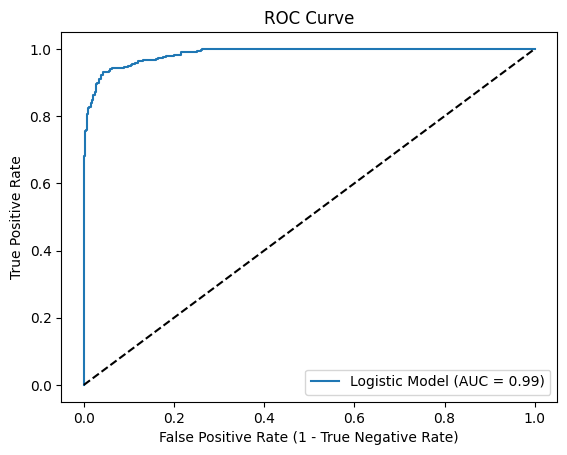

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_train_proba = logistic_model.predict_proba(x_train)[:, 1]
fpr, tpr, thresholds = roc_curve(
    y_train,y_train_proba
)

auc = roc_auc_score(y_train, y_train_proba)

print("AUC:", auc)

plt.plot(fpr, tpr, label='Logistic Model (AUC = %0.2f)' % auc)
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate (1 - True Negative Rate)')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

AUC: 0.9876958411943237


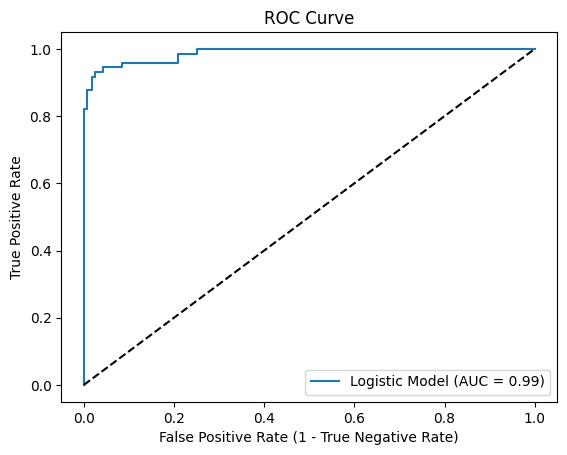

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


y_test_proba = logistic_model.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(
    y_test,y_test_proba
)

auc = roc_auc_score(y_test, y_test_proba)


print("AUC:", auc)

plt.plot(fpr, tpr, label='Logistic Model (AUC = %0.2f)' % auc)
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate (1 - True Negative Rate)')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()